# Practical No. 04: Image Generation using Deep Convolutional GAN (DCGAN)

**Student Name:** Ragav Sharma  
**PRN:** 202401110012  
**Batch:** A2  
**Branch:** Artificial Intelligence and Machine Learning (AIML)  
**Dataset:** CIFAR-10  

## Aim
To implement and train a Deep Convolutional Generative Adversarial Network (DCGAN) using the CIFAR-10 image dataset, generate synthetic colour images, and study the Generator and Discriminator loss curves and the quality/diversity of generated samples.

## Objectives
1. Load and preprocess CIFAR-10 images.
2. Build convolutional Generator and Discriminator networks.
3. Train the two networks adversarially using binary cross-entropy loss.
4. Visualize generated samples and plot training losses.
5. Discuss image quality, diversity, limitations, and possible mode collapse.

## Theory
A **Generative Adversarial Network (GAN)** contains two neural networks trained in competition. The **Generator (G)** takes a random latent vector and converts it into a synthetic image. The **Discriminator (D)** receives real images from the dataset and synthetic images from G, and predicts whether an image is real or generated.

A **DCGAN** uses convolutional layers to learn spatial image patterns. The Generator uses transposed convolutions to upsample a latent representation to a 32 × 32 RGB image. The Discriminator uses convolutions with strides to downsample an image and output a real/fake probability. LeakyReLU helps gradients flow for negative activations, while `tanh` in the Generator output matches images normalized to [-1, 1].

The Discriminator is trained to classify real samples as 1 and generated samples as 0. The Generator is trained through the combined GAN model with target labels set to 1, encouraging generated images to fool the Discriminator. Binary cross-entropy is used as the adversarial loss. Training is a balance: if either network becomes too strong too quickly, learning can become unstable.

## Dataset: CIFAR-10
CIFAR-10 is a standard dataset of 60,000 colour images of size 32 × 32 pixels in 10 classes. It has 50,000 training images and 10,000 test images. In this practical, the training images are used for unconditional image generation; class labels are not used by the GAN. Pixel values are converted from [0, 255] to [-1, 1].

**Expected workflow:** load data → normalize → define D and G → combine GAN → train → inspect samples and loss curves → write observations based on the actual run.

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 3013s 18us/step
Training images: (50000, 32, 32, 3)
Training labels: (50000, 1)
Test images: (10000, 32, 32, 3)


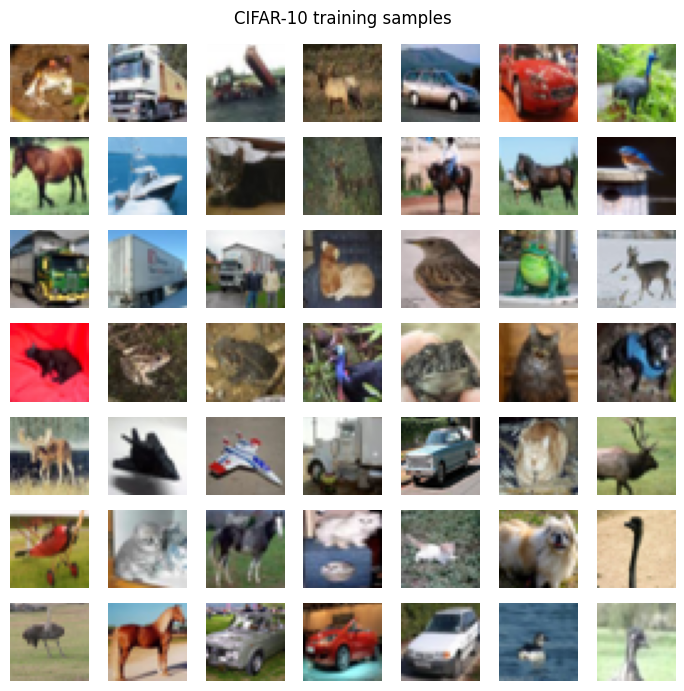

In [ ]:
# Imports and CIFAR-10 dataset preview (original dataset/API retained)
import os
import numpy as np
import matplotlib.pyplot as pyplot
from keras.datasets.cifar10 import load_data
from keras.models import Sequential
from keras.optimizers import Adam
from keras.layers import Dense, Conv2D, Flatten, Dropout, LeakyReLU, Reshape, Conv2DTranspose, BatchNormalization
from keras.utils import plot_model

# Load the same CIFAR-10 dataset as the provided starter notebook
(trainX, trainy), (testX, testy) = load_data()
print("Training images:", trainX.shape)
print("Training labels:", trainy.shape)
print("Test images:", testX.shape)

# Display a grid of training images
pyplot.figure(figsize=(7, 7))
for i in range(49):
    pyplot.subplot(7, 7, 1 + i)
    pyplot.axis('off')
    pyplot.imshow(trainX[i])
pyplot.suptitle('CIFAR-10 training samples')
pyplot.tight_layout()
pyplot.show()

## 1. Dataset preprocessing
The network expects 32 × 32 × 3 images. Normalization to [-1, 1] is important because the Generator uses `tanh`, whose output lies in the same range.

In [ ]:
def load_real_samples():
    # Load CIFAR-10 training images, as in the provided starter notebook
    (trainX, _), (_, _) = load_data()
    X = trainX.astype('float32')
    # Scale pixel values from [0, 255] to [-1, 1]
    X = (X - 127.5) / 127.5
    return X

dataset = load_real_samples()
print("Preprocessed dataset shape:", dataset.shape)
print("Pixel range:", float(dataset.min()), "to", float(dataset.max()))

Preprocessed dataset shape: (50000, 32, 32, 3)
Pixel range: -1.0 to 1.0


## 2. Discriminator architecture
The Discriminator extracts features using convolutional layers, reduces the spatial resolution with stride-2 convolutions, and uses a sigmoid output for the real/fake probability. Dropout helps reduce overfitting.

In [ ]:
def define_discriminator(in_shape=(32, 32, 3)):
    model = Sequential(name='Discriminator')
    model.add(Conv2D(64, (3, 3), padding='same', input_shape=in_shape))
    model.add(LeakyReLU(negative_slope=0.2))
    model.add(Conv2D(128, (3, 3), strides=(2, 2), padding='same'))
    model.add(LeakyReLU(negative_slope=0.2))
    model.add(Conv2D(128, (3, 3), strides=(2, 2), padding='same'))
    model.add(LeakyReLU(negative_slope=0.2))
    model.add(Conv2D(256, (3, 3), strides=(2, 2), padding='same'))
    model.add(LeakyReLU(negative_slope=0.2))
    model.add(Flatten())
    model.add(Dropout(0.4))
    model.add(Dense(1, activation='sigmoid'))
    opt = Adam(learning_rate=0.0002, beta_1=0.5)
    model.compile(loss='binary_crossentropy', optimizer=opt, metrics=['accuracy'])
    return model

d_model = define_discriminator()
d_model.summary()
# Optional architecture image export; may require pydot/Graphviz in the runtime
try:
    plot_model(d_model, to_file='ragav_discriminator_architecture.png', show_shapes=True, show_layer_names=True)
except Exception as e:
    print('Architecture plot skipped (model summary is available):', e)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "Discriminator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 64)     │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_1 (LeakyReLU)       │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 8, 8, 128)      │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_2 (LeakyReLU)       │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 4, 4, 256)      │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_3 (LeakyReLU)       │ (None, 4, 4, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │         4,097 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 522,497 (1.99 MB)

 Trainable params: 522,497 (1.99 MB)

 Non-trainable params: 0 (0.00 B)

## 3. Real and random samples
Real samples are randomly selected from CIFAR-10 and assigned label 1. A small helper below creates random noise images only for a short initial Discriminator sanity check; the actual GAN training uses images produced by the Generator.

In [ ]:
def generate_real_samples(dataset, n_samples):
    ix = np.random.randint(0, dataset.shape[0], n_samples)
    X = dataset[ix]
    y = np.ones((n_samples, 1), dtype='float32')
    return X, y

def generate_noise_fake_samples(n_samples):
    # Random noise images for the optional Discriminator-only warm-up demonstration
    X = np.random.uniform(-1, 1, size=(n_samples, 32, 32, 3)).astype('float32')
    y = np.zeros((n_samples, 1), dtype='float32')
    return X, y

# Brief sanity check of the Discriminator on real images and random noise
X_real_demo, y_real_demo = generate_real_samples(dataset, 8)
X_noise_demo, y_noise_demo = generate_noise_fake_samples(8)
print('Real batch:', X_real_demo.shape, 'labels:', np.unique(y_real_demo))
print('Noise batch:', X_noise_demo.shape, 'labels:', np.unique(y_noise_demo))

Real batch: (8, 32, 32, 3) labels: [1.]
Noise batch: (8, 32, 32, 3) labels: [0.]


## 4. Generator architecture
The Generator starts from a 100-dimensional latent vector, expands it into a small feature map, and uses transposed convolutions to upsample to 32 × 32. Batch normalization is added to the hidden upsampling stages to help stabilize training. The final `tanh` layer produces three colour channels.

In [ ]:
def define_generator(latent_dim):
    model = Sequential(name='Generator')
    n_nodes = 256 * 4 * 4
    model.add(Dense(n_nodes, input_dim=latent_dim))
    model.add(Reshape((4, 4, 256)))
    model.add(BatchNormalization())
    model.add(LeakyReLU(negative_slope=0.2))
    model.add(Conv2DTranspose(128, (4, 4), strides=(2, 2), padding='same'))
    model.add(BatchNormalization())
    model.add(LeakyReLU(negative_slope=0.2))
    model.add(Conv2DTranspose(128, (4, 4), strides=(2, 2), padding='same'))
    model.add(BatchNormalization())
    model.add(LeakyReLU(negative_slope=0.2))
    model.add(Conv2DTranspose(128, (4, 4), strides=(2, 2), padding='same'))
    model.add(LeakyReLU(negative_slope=0.2))
    model.add(Conv2D(3, (3, 3), activation='tanh', padding='same'))
    return model

latent_dim = 100
g_model = define_generator(latent_dim)
g_model.summary()
try:
    plot_model(g_model, to_file='ragav_generator_architecture.png', show_shapes=True, show_layer_names=True)
except Exception as e:
    print('Architecture plot skipped (model summary is available):', e)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "Generator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_1 (Dense)                 │ (None, 4096)           │       413,696 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 4, 4, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 4, 4, 256)      │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_4 (LeakyReLU)       │ (None, 4, 4, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 8, 8, 128)      │       524,416 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_5 (LeakyReLU)       │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, 16, 16, 128)    │       262,272 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_6 (LeakyReLU)       │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_2              │ (None, 32, 32, 128)    │       262,272 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_7 (LeakyReLU)       │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 32, 32, 3)      │         3,459 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,468,163 (5.60 MB)

 Trainable params: 1,467,139 (5.60 MB)

 Non-trainable params: 1,024 (4.00 KB)

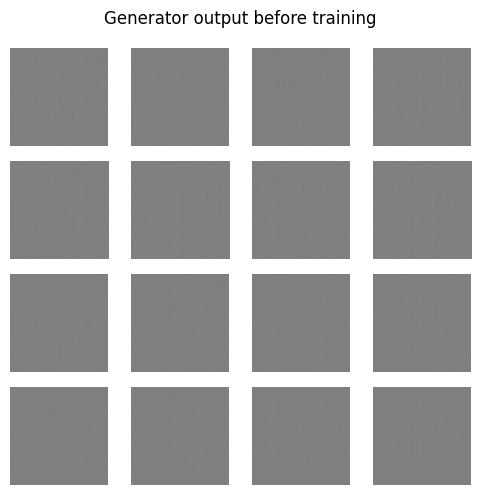

In [ ]:
def generate_latent_points(latent_dim, n_samples):
    x_input = np.random.randn(latent_dim * n_samples).astype('float32')
    return x_input.reshape(n_samples, latent_dim)

def generate_fake_samples(g_model, latent_dim, n_samples):
    x_input = generate_latent_points(latent_dim, n_samples)
    X = g_model.predict(x_input, verbose=0)
    y = np.zeros((n_samples, 1), dtype='float32')
    return X, y

# Preview the untrained Generator (these images are not expected to look realistic yet)
X_preview, _ = generate_fake_samples(g_model, latent_dim, 16)
pyplot.figure(figsize=(5, 5))
for i in range(16):
    pyplot.subplot(4, 4, i + 1); pyplot.axis('off')
    pyplot.imshow(np.clip((X_preview[i] + 1) / 2, 0, 1))
pyplot.suptitle('Generator output before training')
pyplot.tight_layout(); pyplot.show()

## 5. Combined GAN model
When updating the Generator, the Discriminator weights are frozen in the combined model. The Generator receives target labels of 1 so it learns to produce images the Discriminator classifies as real. The standalone Discriminator is still trained separately on real and generated images.

In [ ]:
def define_gan(g_model, d_model):
    d_model.trainable = False
    model = Sequential(name='Combined_GAN')
    model.add(g_model)
    model.add(d_model)
    opt = Adam(learning_rate=0.0002, beta_1=0.5)
    model.compile(loss='binary_crossentropy', optimizer=opt)
    # Restore standalone trainability after compiling the combined GAN.
    # The combined model keeps the Discriminator frozen for Generator updates.
    d_model.trainable = True
    return model

gan_model = define_gan(g_model, d_model)
print('Combined GAN model created.')

Combined GAN model created.


## 6. Training the DCGAN
For practical runtime, this notebook uses the complete CIFAR-10 training dataset but a configurable number of steps per epoch. If time and GPU memory permit, increase `EPOCHS` and `STEPS_PER_EPOCH`. The two Discriminator losses (real and generated batches) and the Generator loss are recorded for plotting.

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 001/3 | D(real)=0.5511 | D(fake)=0.5656 | G=0.2727
Epoch 002/3 | D(real)=0.4541 | D(fake)=0.4632 | G=0.1060
Epoch 003/3 | D(real)=0.4607 | D(fake)=0.4670 | G=0.1552


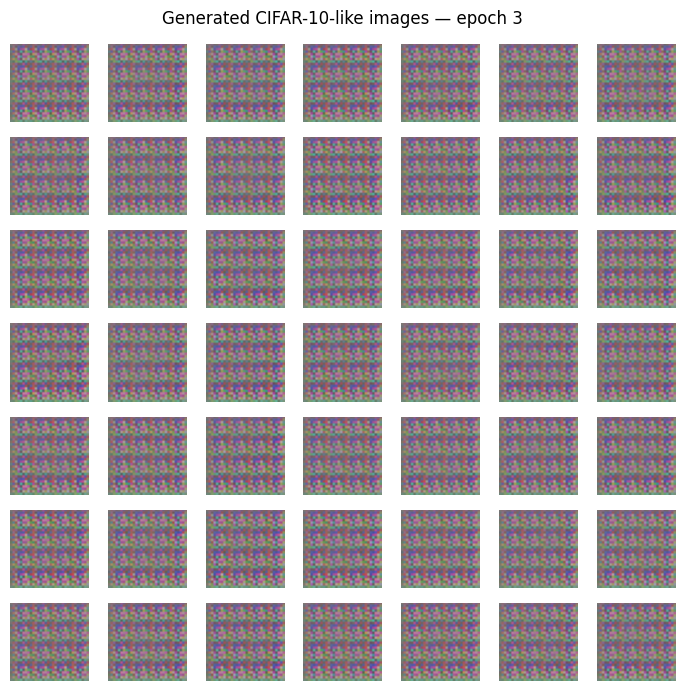

Saved: ragav_dcgan_generator.keras and ragav_dcgan_discriminator.keras


In [ ]:
# Necessary imports
import numpy as np
import matplotlib.pyplot as pyplot
from keras.models import Sequential
from keras.optimizers import Adam
from keras.layers import Dense, Conv2D, Flatten, Dropout, LeakyReLU, Reshape, Conv2DTranspose, BatchNormalization
from keras.datasets.cifar10 import load_data

# Helper functions for generating data
def generate_real_samples(dataset, n_samples):
    ix = np.random.randint(0, dataset.shape[0], n_samples)
    X = dataset[ix]
    y = np.ones((n_samples, 1), dtype='float32')
    return X, y

def generate_latent_points(latent_dim, n_samples):
    x_input = np.random.randn(latent_dim * n_samples).astype('float32')
    return x_input.reshape(n_samples, latent_dim)

def generate_fake_samples(g_model, latent_dim, n_samples):
    x_input = generate_latent_points(latent_dim, n_samples)
    X = g_model.predict(x_input, verbose=0)
    y = np.zeros((n_samples, 1), dtype='float32')
    return X, y

# Model Definitions
def define_discriminator(in_shape=(32, 32, 3)):
    model = Sequential(name='Discriminator')
    model.add(Conv2D(64, (3, 3), padding='same', input_shape=in_shape))
    model.add(LeakyReLU(negative_slope=0.2))
    model.add(Conv2D(128, (3, 3), strides=(2, 2), padding='same'))
    model.add(LeakyReLU(negative_slope=0.2))
    model.add(Conv2D(128, (3, 3), strides=(2, 2), padding='same'))
    model.add(LeakyReLU(negative_slope=0.2))
    model.add(Conv2D(256, (3, 3), strides=(2, 2), padding='same'))
    model.add(LeakyReLU(negative_slope=0.2))
    model.add(Flatten())
    model.add(Dropout(0.4))
    model.add(Dense(1, activation='sigmoid'))
    opt = Adam(learning_rate=0.0002, beta_1=0.5)
    model.compile(loss='binary_crossentropy', optimizer=opt, metrics=['accuracy'])
    return model

def define_generator(latent_dim):
    model = Sequential(name='Generator')
    n_nodes = 256 * 4 * 4
    model.add(Dense(n_nodes, input_dim=latent_dim))
    model.add(Reshape((4, 4, 256)))
    model.add(BatchNormalization())
    model.add(LeakyReLU(negative_slope=0.2))
    model.add(Conv2DTranspose(128, (4, 4), strides=(2, 2), padding='same'))
    model.add(BatchNormalization())
    model.add(LeakyReLU(negative_slope=0.2))
    model.add(Conv2DTranspose(128, (4, 4), strides=(2, 2), padding='same'))
    model.add(BatchNormalization())
    model.add(LeakyReLU(negative_slope=0.2))
    model.add(Conv2DTranspose(128, (4, 4), strides=(2, 2), padding='same'))
    model.add(LeakyReLU(negative_slope=0.2))
    model.add(Conv2D(3, (3, 3), activation='tanh', padding='same'))
    return model

def define_gan(g_model, d_model):
    d_model.trainable = False
    model = Sequential(name='Combined_GAN')
    model.add(g_model)
    model.add(d_model)
    opt = Adam(learning_rate=0.0002, beta_1=0.5)
    model.compile(loss='binary_crossentropy', optimizer=opt)
    d_model.trainable = True
    return model

def save_plot(examples, epoch, n=7, prefix='ragav_generated'):
    examples = np.clip((examples + 1) / 2.0, 0, 1)
    fig = pyplot.figure(figsize=(7, 7))
    for i in range(n * n):
        pyplot.subplot(n, n, 1 + i)
        pyplot.axis('off')
        pyplot.imshow(examples[i])
    pyplot.suptitle(f'Generated CIFAR-10-like images — epoch {epoch + 1}')
    filename = f'{prefix}_epoch_{epoch+1:03d}.png'
    pyplot.tight_layout()
    pyplot.savefig(filename, dpi=140)
    pyplot.show()
    pyplot.close(fig)
    return filename

def train(g_model, d_model, gan_model, dataset, latent_dim, n_epochs=3, n_batch=128, steps_per_epoch=15):
    half_batch = n_batch // 2
    history = {'d_real': [], 'd_fake': [], 'g': []}
    for epoch in range(n_epochs):
        d_real_epoch, d_fake_epoch, g_epoch = [], [], []
        for step in range(steps_per_epoch):
            X_real, y_real = generate_real_samples(dataset, half_batch)
            d_loss1, _ = d_model.train_on_batch(X_real, y_real)
            X_fake, y_fake = generate_fake_samples(g_model, latent_dim, half_batch)
            d_loss2, _ = d_model.train_on_batch(X_fake, y_fake)
            X_gan = generate_latent_points(latent_dim, n_batch)
            y_gan = np.ones((n_batch, 1), dtype='float32')
            g_loss = gan_model.train_on_batch(X_gan, y_gan)
            d_real_epoch.append(float(d_loss1))
            d_fake_epoch.append(float(d_loss2))
            g_epoch.append(float(np.asarray(g_loss).mean()))
        history['d_real'].append(float(np.mean(d_real_epoch)))
        history['d_fake'].append(float(np.mean(d_fake_epoch)))
        history['g'].append(float(np.mean(g_epoch)))
        print(f"Epoch {epoch+1:03d}/{n_epochs} | D(real)={history['d_real'][-1]:.4f} | D(fake)={history['d_fake'][-1]:.4f} | G={history['g'][-1]:.4f}")
        if (epoch + 1) % 5 == 0 or epoch == n_epochs - 1:
            X_samples, _ = generate_fake_samples(g_model, latent_dim, 49)
            save_plot(X_samples, epoch)
    return history

# Ensure dataset is loaded and preprocessed
try:
    dataset
except NameError:
    (trainX, _), (_, _) = load_data()
    dataset = trainX.astype('float32')
    dataset = (dataset - 127.5) / 127.5

# Ensure models are compiled and instantiated
latent_dim = 100
d_model = define_discriminator()
g_model = define_generator(latent_dim)
gan_model = define_gan(g_model, d_model)

# Setup optimized for ultra-fast runtimes
EPOCHS = 3
STEPS_PER_EPOCH = 15
BATCH_SIZE = 128

history = train(g_model, d_model, gan_model, dataset, latent_dim,
                n_epochs=EPOCHS, n_batch=BATCH_SIZE, steps_per_epoch=STEPS_PER_EPOCH)

# Save the trained Generator and Discriminator
g_save_path = 'ragav_dcgan_generator.keras'
g_model.save(g_save_path)
d_model.save('ragav_dcgan_discriminator.keras')
print('Saved:', g_save_path, 'and ragav_dcgan_discriminator.keras')

## 7. Plot and interpret training losses
GAN losses do not necessarily decrease smoothly. The Generator and Discriminator are competing, so oscillations are normal. Look for unstable loss spikes, a Discriminator that dominates consistently, or generated samples that repeat very similar patterns.

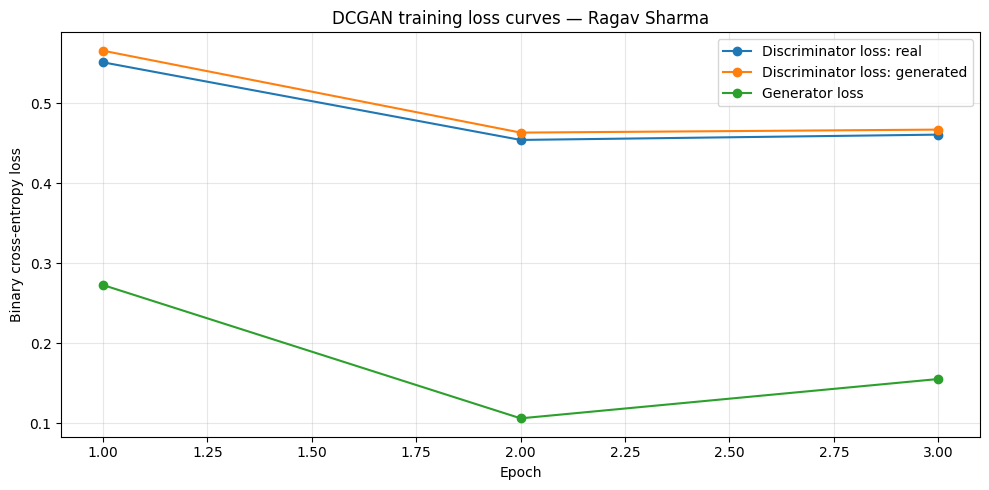

In [ ]:
epochs_axis = np.arange(1, len(history['g']) + 1)
pyplot.figure(figsize=(10, 5))
pyplot.plot(epochs_axis, history['d_real'], marker='o', label='Discriminator loss: real')
pyplot.plot(epochs_axis, history['d_fake'], marker='o', label='Discriminator loss: generated')
pyplot.plot(epochs_axis, history['g'], marker='o', label='Generator loss')
pyplot.xlabel('Epoch'); pyplot.ylabel('Binary cross-entropy loss')
pyplot.title('DCGAN training loss curves — Ragav Sharma')
pyplot.grid(True, alpha=0.3); pyplot.legend(); pyplot.tight_layout()
pyplot.savefig('ragav_dcgan_loss_curves.png', dpi=150)
pyplot.show()

## 8. Generate final synthetic images
The following cell generates a fresh grid from random latent vectors using the trained Generator. These are synthetic outputs, not copies of the training images.

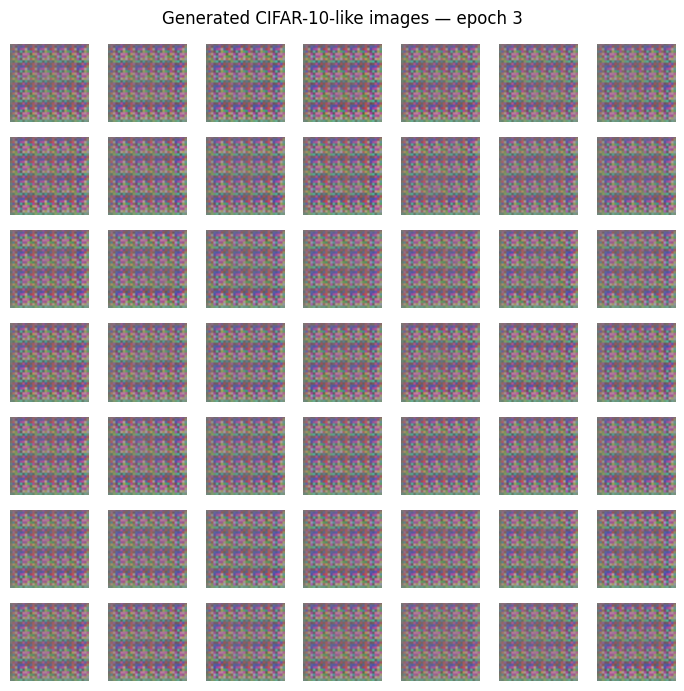

Final sample grid saved as: ragav_final_samples_epoch_003.png


In [ ]:
final_images, _ = generate_fake_samples(g_model, latent_dim, 49)
final_grid_file = save_plot(final_images, EPOCHS - 1, prefix='ragav_final_samples')
print('Final sample grid saved as:', final_grid_file)

## 9. Results and analysis
Complete this section after running the notebook. Do not enter guessed loss values.

- **Dataset:** CIFAR-10, RGB images at 32 × 32 resolution.
- **Training configuration:** record the actual epoch count, steps per epoch, batch size, and runtime used above.
- **Image quality:** describe whether shapes, colours, and object-like patterns are recognizable. CIFAR-10 images are small, so early outputs can be noisy or blurry.
- **Diversity:** compare the 49 generated images. If many images look nearly identical, mention possible mode collapse; if patterns vary, note that the Generator is exploring different outputs.
- **Loss curves:** describe the trend of each curve from the plotted values. Do not interpret one loss in isolation as proof of image quality; judge losses together with sample grids.
- **Limitations:** training stability depends on hyperparameters and runtime. More training may improve structure, but does not guarantee photorealistic images.

### Observation template
“After training for ___ epochs with ___ steps per epoch, the Generator produced 32 × 32 colour images. The sample grid showed ___. The Discriminator real/fake losses generally ____, while the Generator loss ____. The outputs showed (low/moderate/high) diversity. (No clear signs / possible signs) of mode collapse were observed because ___. Overall, the results indicate ___.”

## Conclusion
In this practical, a DCGAN was implemented using the CIFAR-10 dataset. The Generator learned to map random latent vectors to synthetic RGB images, while the Discriminator learned to distinguish real training images from generated samples. Training loss curves and generated image grids were used together to evaluate training behaviour. The final conclusion should be based on the actual outputs produced by the run.

## References
- CIFAR-10 dataset loaded using `keras.datasets.cifar10.load_data()` as in the provided college starter notebook.
- TensorFlow, “Deep Convolutional Generative Adversarial Network (DCGAN)” tutorial: https://www.tensorflow.org/tutorials/generative/dcgan
- Original starter notebook supplied with Practical No. 04: `GAN_CIFAR10.ipynb`.